In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score,confusion_matrix

In [8]:
df = pd.read_csv("Admission_Predict.csv")
df.columns = df.columns.str.strip()

threshold = df["Chance of Admit"].quantile(0.75)
print(f"Top 25 percentile Threshold Value: {threshold:.4f}")

df["Chance of Admit"] = (df["Chance of Admit"] >= threshold).astype(int)

print("Class Distribution:")
print(df["Chance of Admit"].value_counts())


Top 25 percentile Threshold Value: 0.8300
Class Distribution:
Chance of Admit
0    299
1    101
Name: count, dtype: int64


In [9]:
RANDOM_STATE = 42

In [10]:
features = ["GRE Score", "TOEFL Score", "University Rating", "SOP", "LOR", "CGPA", "Research"]

X = df[features]
y = df["Chance of Admit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=RANDOM_STATE, stratify=y
)


In [11]:
dt_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)
dt_gini.fit(X_train, y_train)
y_train_pred_gini = dt_gini.predict(X_train)
y_test_pred_gini = dt_gini.predict(X_test)

dt_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)
dt_entropy.fit(X_train, y_train)
y_train_pred_entropy = dt_entropy.predict(X_train)
y_test_pred_entropy = dt_entropy.predict(X_test)

print("=== GINI METRICS ===")
print("Train Accuracy: ", f"{accuracy_score(y_train, y_train_pred_gini):.2f}")
print("Test Accuracy:  ", f"{accuracy_score(y_test, y_test_pred_gini):.2f}")
print("Train Precision:", f"{precision_score(y_train, y_train_pred_gini):.2f}")
print("Test Precision: ", f"{precision_score(y_test, y_test_pred_gini):.2f}")
print("Train Recall:   ", f"{recall_score(y_train, y_train_pred_gini):.2f}")
print("Test Recall:    ", f"{recall_score(y_test, y_test_pred_gini):.2f}")
print("Train F1 Score: ", f"{f1_score(y_train, y_train_pred_gini):.2f}")
print("Test F1 Score:  ", f"{f1_score(y_test, y_test_pred_gini):.2f}")

print("\n=== ENTROPY METRICS ===")
print("Train Accuracy: ", f"{accuracy_score(y_train, y_train_pred_entropy):.2f}")
print("Test Accuracy:  ", f"{accuracy_score(y_test, y_test_pred_entropy):.2f}")
print("Train Precision:", f"{precision_score(y_train, y_train_pred_entropy):.2f}")
print("Test Precision: ", f"{precision_score(y_test, y_test_pred_entropy):.2f}")
print("Train Recall:   ", f"{recall_score(y_train, y_train_pred_entropy):.2f}")
print("Test Recall:    ", f"{recall_score(y_test, y_test_pred_entropy):.2f}")
print("Train F1 Score: ", f"{f1_score(y_train, y_train_pred_entropy):.2f}")
print("Test F1 Score:  ", f"{f1_score(y_test, y_test_pred_entropy):.2f}")


=== GINI METRICS ===
Train Accuracy:  0.96
Test Accuracy:   0.91
Train Precision: 0.92
Test Precision:  0.78
Train Recall:    0.90
Test Recall:     0.90
Train F1 Score:  0.91
Test F1 Score:   0.84

=== ENTROPY METRICS ===
Train Accuracy:  0.96
Test Accuracy:   0.91
Train Precision: 0.92
Test Precision:  0.78
Train Recall:    0.90
Test Recall:     0.90
Train F1 Score:  0.91
Test F1 Score:   0.84


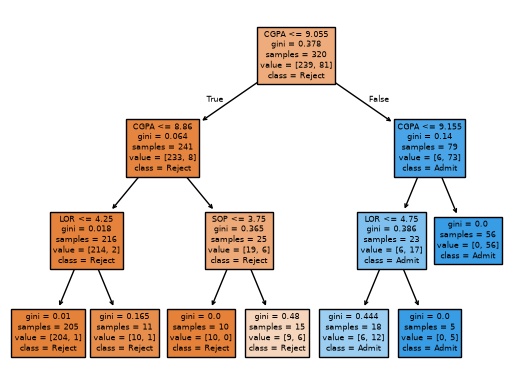

In [12]:
plot_tree(dt_gini, feature_names=features, class_names=["Reject", "Admit"], filled=True)
plt.show()


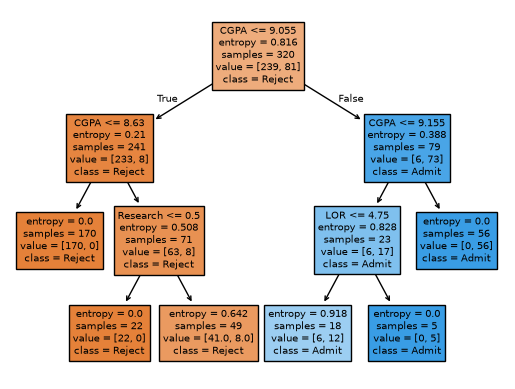

In [13]:
plot_tree(dt_entropy, feature_names=features, class_names=["Reject", "Admit"], filled=True)
plt.show()


# Naive Bayes

In [14]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

nb_train_preds = nb_model.predict(X_train)
nb_test_preds = nb_model.predict(X_test)

print("--- NAIVE BAYES: TRAIN PERFORMANCE ---")
print(classification_report(y_train, nb_train_preds, digits=2))

print("--- NAIVE BAYES: TEST PERFORMANCE ---")
print(classification_report(y_test, nb_test_preds, digits=2))


--- NAIVE BAYES: TRAIN PERFORMANCE ---
              precision    recall  f1-score   support

           0       0.97      0.91      0.94       239
           1       0.78      0.93      0.85        81

    accuracy                           0.92       320
   macro avg       0.88      0.92      0.89       320
weighted avg       0.92      0.92      0.92       320

--- NAIVE BAYES: TEST PERFORMANCE ---
              precision    recall  f1-score   support

           0       0.98      0.93      0.96        60
           1       0.83      0.95      0.88        20

    accuracy                           0.94        80
   macro avg       0.90      0.94      0.92        80
weighted avg       0.94      0.94      0.94        80



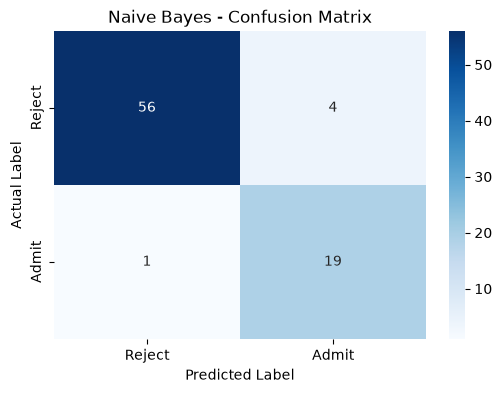

In [16]:
cm = confusion_matrix(y_test, nb_test_preds)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Reject", "Admit"],
            yticklabels=["Reject", "Admit"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()


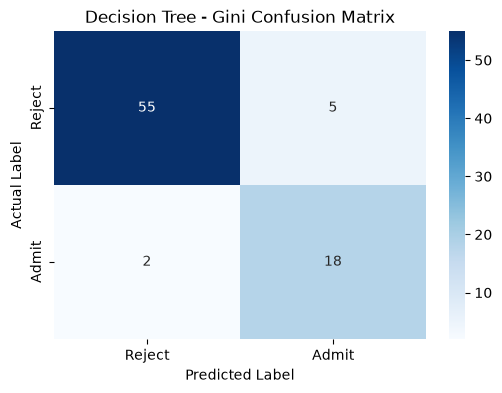

In [17]:
cm_gini = confusion_matrix(y_test, y_test_pred_gini)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_gini, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Reject", "Admit"],
            yticklabels=["Reject", "Admit"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Gini Confusion Matrix")
plt.show()


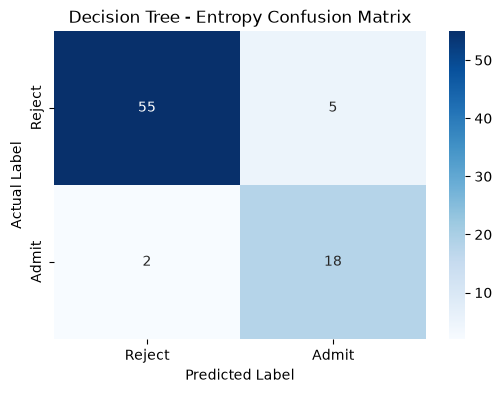

In [20]:
cm_entropy = confusion_matrix(y_test, y_test_pred_entropy)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_entropy, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Reject", "Admit"],
            yticklabels=["Reject", "Admit"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Entropy Confusion Matrix")
plt.show()
